# Example: RMDC26_001279 — a blind Roman event with a high-magnification cusp approach

The fourth blind example on simulated Roman data, after `example_rmdc26_000026` (a planetary caustic),
`example_rmdc26_001422` (a central caustic with a close/wide degeneracy) and `example_rmdc26_001576` (a resonant
caustic). Here the source passes within about one source radius of a cusp of the *central* caustic at a
magnification above 100, and the peak breaks up into two spikes and a shoulder within five hours.

This event teaches two things the earlier ones did not:

* **Where the guided starts fail.** The screen used before (the single-lens trajectory at 360 angles) finds nothing
  better than χ² ≈ 62 000 for 1384 points. Starts built from the times of the two spikes, as if they
  were caustic crossings (Cassan 2008), find the solution in one go.
* **Valleys thinner than the lattice.** The two minima (close and wide) are each narrower than one coarse map step
  in log *s*; the coarse map grazes them at Δχ² ≈ 230 and 64× zooms are needed to resolve them.

**The data.** RMDC26_001279 is an event of the *Experienced tier* of the Roman Microlensing Data Challenge 2026
(RGES-PIT; public domain, CC0, [huggingface.co/datasets/RGES-PIT/Experienced](https://huggingface.co/datasets/RGES-PIT/Experienced)),
simulated with GULLS (Penny et al. 2019). The true parameters are not published, so this is a **blind** analysis.
The extinction is low for a bulge field (1.4, 0.6 and 0.2 mag in F087, F146 and F213), so all three filters
see the event.

**Runtime.** On a 14-core Intel Core i5-13500 (20 threads): guided fits 85 minutes (most of it in the caustic-crossing
starts), coarse map 13 minutes, zooms 5 + 5 + 4 + 4 minutes, polish about 30 minutes. Everything is stored in `data/`,
so the notebook runs in a few seconds by default; `RECOMPUTE = True` computes it all again (about 2.5 hours).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (about 2.5 hours on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc1279_photometry.csv`: all points (none saturated), with `set` (filter), `t` (BJD − 2460000) and `flux`,
`flux_err` in micro-Jansky as provided. Magnitudes below are AB, 23.9 − 2.5 log₁₀(flux / µJy).

In [2]:
SETS = ["F087", "F146", "F213"]
rows = np.genfromtxt("data/rmdc1279_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: 23.9 - 2.5 * np.log10(f)                # AB magnitude of a flux in micro-Jansky
for n in SETS:
    t, f, e = sel(rows, n)
    print(f"{n}: {len(t)} points, median flux {np.median(f):9.4f} uJy, median error {np.median(e):.4f} uJy")

F087: 1501 points, median flux    7.6271 uJy, median error 0.3259 uJy
F146: 46488 points, median flux   33.6267 uJy, median error 0.2533 uJy
F213: 1499 points, median flux  157.5773 uJy, median error 1.0746 uJy


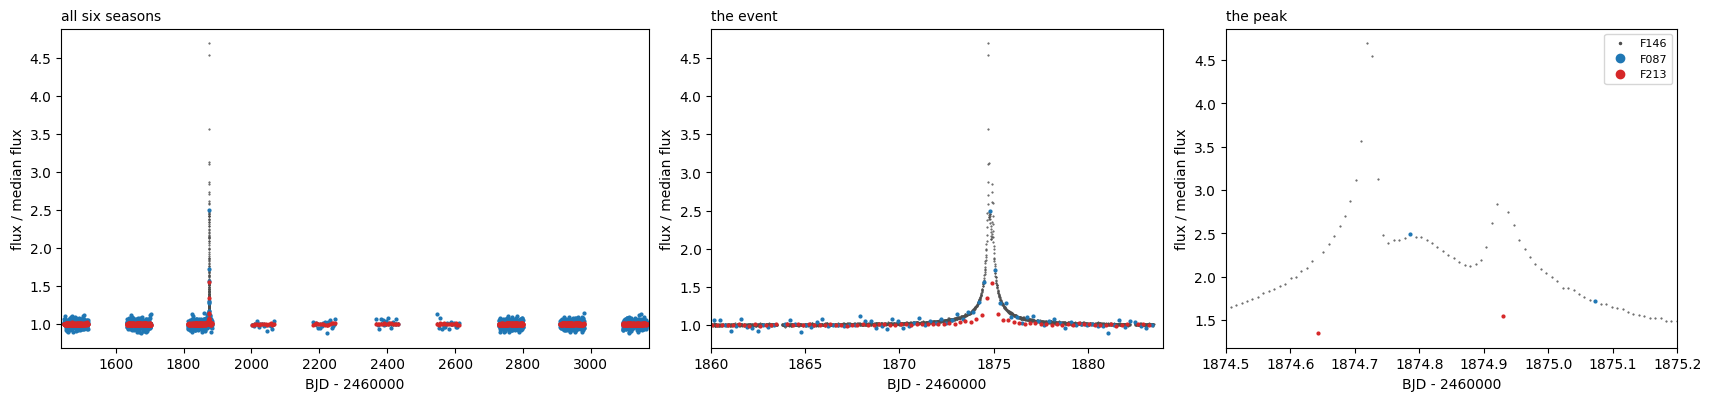

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1]), constrained_layout=True)
for ax, (a, b) in zip(axs, ((1440, 3170), (1860, 1884), (1874.5, 1875.2))):
    for n, c in (("F146", "0.3"), ("F087", "C0"), ("F213", "C3")):
        k = data_all.names.index(n)
        m = (data_all.idx == k) & (data_all.t > a) & (data_all.t < b)
        ax.plot(data_all.t[m], data_all.f[m] / np.median(data_all.f[data_all.idx == k]), ".", ms=1 if n == "F146" else 4,
                color=c, label=n, rasterized=True)
    ax.set_xlim(a, b); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("flux / median flux")
axs[0].set_title("all six seasons", loc="left", fontsize=10)
axs[1].set_title("the event", loc="left", fontsize=10)
axs[2].set_title("the peak", loc="left", fontsize=10); axs[2].legend(fontsize=8, markerscale=3)

The event peaks at BJD′ = 1874.8 (BJD′ = BJD − 2460000), nine days before the end of the third season. It is short
(a few days) and the peak is sharp and broken: a steep rise to a spike, a fall to a broad shoulder, a dip and a second
spike, all within about five hours. The baseline is dominated by other stars (F146 brightens by a factor of
about 5, although the source is magnified more than 100 times; see below).

## 2. Reducing the data for the maps

The same reduction as in the other examples: the third season only (BJD′ 1813–1884), F146 at full cadence over
the peak (BJD′ 1873.5–1876.0), in 1-hour bins within one Einstein timescale of the single-lens screen fit
(*t*₀ = 1874.8, *t*ₑ = 4.12 d) and 3-hour bins elsewhere; F087 and F213 unbinned.

In [4]:
SEASON = (1813.0, 1884.0)
ANOM = (1873.5, 1876.0)
T0_BIN, TE_BIN = 1874.8, 4.12
def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        key = np.floor((t - SEASON[0]) / np.where(inner, 1 / 24, 3 / 24)).astype(int) * 2 + inner
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T, F, E = (np.r_[t[full], np.bincount(inv, w * t[b]) / W], np.r_[f[full], np.bincount(inv, w * f[b]) / W],
                   np.r_[e[full], W ** -0.5])
        o = np.argsort(T)
        out[n] = (T[o], F[o], E[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49488 points, season 8155, binned 1384: {'F087': 241, 'F146': 903, 'F213': 240}


## 3. Finding the solution: caustic-crossing starts

The guided screen of the earlier examples puts the source on the single-lens trajectory and tries 360 angles for
each (*s*, *q*, ρ). Here it fails: the best of its fits ends at χ² ≈ 62 000 for 1384 points. The peak is too
structured; a start whose trajectory misses the right cusp by a few source radii has no slope to follow.

`lenscape.fit.fit_point` can instead start from **caustic crossings** (Cassan 2008): given the times at which the
source enters and leaves the caustic, it places the trajectory through the caustic of each (*s*, *q*) so that it
crosses at those times, and fits from there. The two spikes are taken as the trial pairs: the first and the second
(BJD′ 1874.715 and 1874.925), and two short pairs around the first spike. On a grid of
log *s* = −0.6 … 0.6 (step 0.1) and log *q* = −4 … 0 (step 0.5), the 8 best distinct results are fitted in all seven
parameters, plus the offset partners of the 4 best. (The source turns out not to cross the caustic, only to pass close
to two of its cusps, but these starts put it close enough.)

In [5]:
first_file = "data/rmdc1279_first_fits.json"
if RECOMPUTE or not os.path.exists(first_file):
    log("computing the guided fits (caustic-crossing starts)")
    from multiprocessing import get_context
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [1874.8, u0, tE, -2.5], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.02, 0.05, 0.1) for tE in (5.0, 10.0, 20.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    CROSS = [(1874.715, 1874.925), (1874.69, 1874.735), (1874.70, 1874.75)]
    CFG = dict(lenscape.config.DEFAULT, seed=dict(t0=sl["t0"], u0=max(sl["u0"], 0.005), tE=sl["tE"], logrho=-3.0),
               caustic_crossings=CROSS, n_caustic=6, caustic_samples=32, n_screen=4)
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    def point(a):
        try:
            c, x = lenscape.fit.fit_point(a[0], a[1], data, CFG)
            return float(c), [float(x[0]), float(x[1]), float(x[2]), a[0], a[1], float(x[3]), float(x[4])]
        except Exception:
            return np.inf, None
    def full_fit(p):
        c, p = lenscape.fit_full(data, np.array(p), grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        return float(c), [float(v) for v in p]
    pts = [(round(a, 3), round(b, 3)) for a in np.arange(-0.6, 0.601, 0.1) for b in np.arange(-4.0, 0.01, 0.5)]
    with get_context("fork").Pool() as pool:               # about 80 minutes on 20 threads
        res = sorted([r for r in pool.map(point, pts) if r[1] is not None], key=lambda r: r[0])
        starts = []
        for c, p in res:
            if all(abs(p[3] - q[3]) > 0.15 or abs(p[4] - q[4]) > 0.6 for _, q in starts):
                starts.append((c, p))
        fits = pool.map(full_fit, [p for _, p in starts[:8]])
        fits += pool.map(full_fit, [lenscape.fit.offset_partner(np.array(p)).tolist() for _, p in sorted(fits)[:4]])
    json.dump(dict(single_lens=sl, fits=sorted(fits), caustic_fits=dict(crossings=CROSS, grid=res, fits=sorted(fits))),
              open(first_file, "w"), indent=1)
first = json.load(open(first_file))
print(f"crossing pairs tried: {first['caustic_fits']['crossings']}")
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>8s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in sorted(first["caustic_fits"]["fits"]):
    if all(abs(p[3] - q[3]) > 0.003 or abs(p[4] - q[4]) > 0.03 for _, q in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+8.5f} {p[2]:7.3f} {p[6]:+7.3f}")
best_first = np.array(first["fits"][0][1])

crossing pairs tried: [[1874.715, 1874.925], [1874.69, 1874.735], [1874.7, 1874.75]]
     chi2    log s   log q  alpha       u0      tE log rho
  1373.62  +0.1087  -2.259  1.318 -0.01779   6.362  -2.745
  1401.05  -0.1143  -2.271  1.313 -0.01479   6.454  -2.762
 16283.28  -0.7340  -0.383  2.588 +0.01578   6.816  -5.000
 19427.36  +0.6924  -0.752  5.398 +0.53426   6.966  -3.144
 19969.25  +0.7173  -0.382  4.244 +1.33269   6.678  -5.000
 23612.72  +0.4896  -1.342  2.699 -0.04079   7.965  -2.676
 37204.02  +0.1155  -2.287  5.152 -0.03825   3.391  -2.373
 41066.15  -0.5241  -1.455  3.138 -0.00102  35.087  -3.061
100802.10  -0.8743  +0.286  1.393 +1.05640  21.652  -2.022
117063.52  +1.7616 +45.834  2.150 +0.26703   1.004  -0.483


Two fits stand out, a **wide** one (log *s* = +0.109, χ² = 1373.6 for 1384 binned points) and a **close** one
(log *s* = −0.114, 27 higher), both with log *q* ≈ −2.26. Everything else ends about 15 000 higher or more. The pair
is the classic close/wide degeneracy of central caustics (*s* ↔ 1/*s*), here broken clearly by the data.

In [6]:
close_first = np.array([p for c, p in first["fits"] if p[3] < 0][0])
check = {"wide": best_first, "close": close_first}
c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
print(f"{'':7s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the wide fit)")
for k, v in c.items():
    print(f"{k:7s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c["wide"])))
print(f"wide fit: chi2 = {c['wide'][0]:.1f} (binned, N = {len(data)}), {c['wide'][1]:.1f} (season, N = {len(season)}), "
      f"{c['wide'][2]:.1f} (all, N = {len(data_all)})")

            binned     season        all   (Delta chi2 to the wide fit)
wide          0.00       0.00       0.00
close        27.43      27.44      27.43
wide fit: chi2 = 1373.6 (binned, N = 1384), 7853.0 (season, N = 8155), 49184.6 (all, N = 49488)


The binned data reproduce the Δχ² of the unbinned season and of all six seasons.

## 4. The coarse map

The same lattice as before: −1 ≤ log *s* ≤ 1 in steps of 0.04, −5 ≤ log *q* ≤ 0 in steps of 0.1, 51 × 51
points, no refinement more than 500 above the minimum. **Runtime: 13 minutes.**

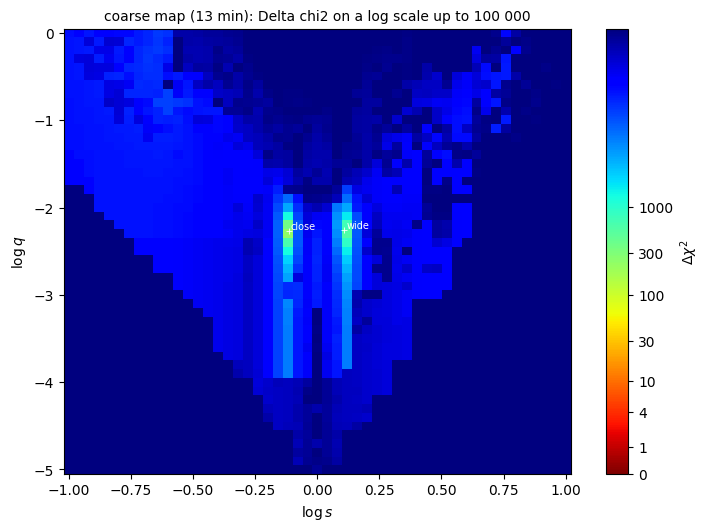

In [7]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc1279_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc1279_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-1.0, 1.0001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, 0.0001, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
ref0 = first["fits"][0][0]
fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
figures.plot_map(map1, ax=ax, vmax=100000, chi2_ref=ref0, marks={"wide": best_first[3:5], "close": close_first[3:5]})
ax.set_title(f"coarse map ({map1['wall'] / 60:.0f} min): Delta chi2 on a log scale up to 100 000", fontsize=10);

The map is a broad V, as for the other central-caustic event (RMDC26_001422), but with a striking feature: two thin
vertical stripes at log *s* ≈ ±0.12, from log *q* ≈ −4 up to −2, where Δχ² drops from tens of thousands to a few
hundred. These are the lattice columns closest to the two solutions. Along each stripe the central caustic keeps
roughly the right size (a heavier companion needs to be further from the Einstein ring), but only near
log *q* ≈ −2.26 does its shape also fit the spikes and the shoulder. The lowest lattice point is still about 230 above the best
fit: the valleys are narrower than the lattice step of 0.04 in log *s*, and the lattice points at ±0.12 lie beside
them, not in them.

## 5. Zooming into the two valleys

`lenscape.maps.densify` refines boxes aligned with the coarse lattice, first at 8× in log *s* and 4× in log *q*
(0.005 × 0.025) around each stripe, then at 64× × 16× (0.000625 × 0.00625) around each minimum.

In [8]:
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
dens = lambda prev, s, q, fs, fq: lenscape.maps.densify(prev, data, step(*s, -1.0, 0.04 / fs), step(*q, -5.0, 0.1 / fq),
                                                         best=best_first, bin_wings=False, log=log)
mapw8 = run_or_load("wide_8x", lambda: dens([map1], (0.06, 0.16), (-2.8, -1.8), 8, 4))
mapc8 = run_or_load("close_8x", lambda: dens([map1], (-0.16, -0.06), (-2.8, -1.8), 8, 4))
mapw64 = run_or_load("wide_64x", lambda: dens([mapw8, map1], (0.100, 0.120), (-2.40, -2.10), 64, 16))
mapc64 = run_or_load("close_64x", lambda: dens([mapc8, map1], (-0.125, -0.105), (-2.42, -2.12), 64, 16))
MAPS = [("coarse", map1), ("wide 8x", mapw8), ("close 8x", mapc8), ("wide 64x", mapw64), ("close 64x", mapc64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:10s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest point "
          f"{m['chi2'][i, j] - ref:7.2f} at log s = {m['logs'][i]:+.6f}, log q = {m['logq'][j]:.5f}")

coarse    : 51 x 51 points, 13.4 min, lowest point  233.24 at log s = -0.120000, log q = -2.30000
wide 8x   : 21 x 41 points,  4.8 min, lowest point   11.30 at log s = +0.110000, log q = -2.25000
close 8x  : 21 x 41 points,  5.0 min, lowest point   31.41 at log s = -0.115000, log q = -2.27500
wide 64x  : 33 x 49 points,  3.5 min, lowest point    0.00 at log s = +0.108750, log q = -2.26250
close 64x : 33 x 48 points,  4.0 min, lowest point   27.45 at log s = -0.114375, log q = -2.26875


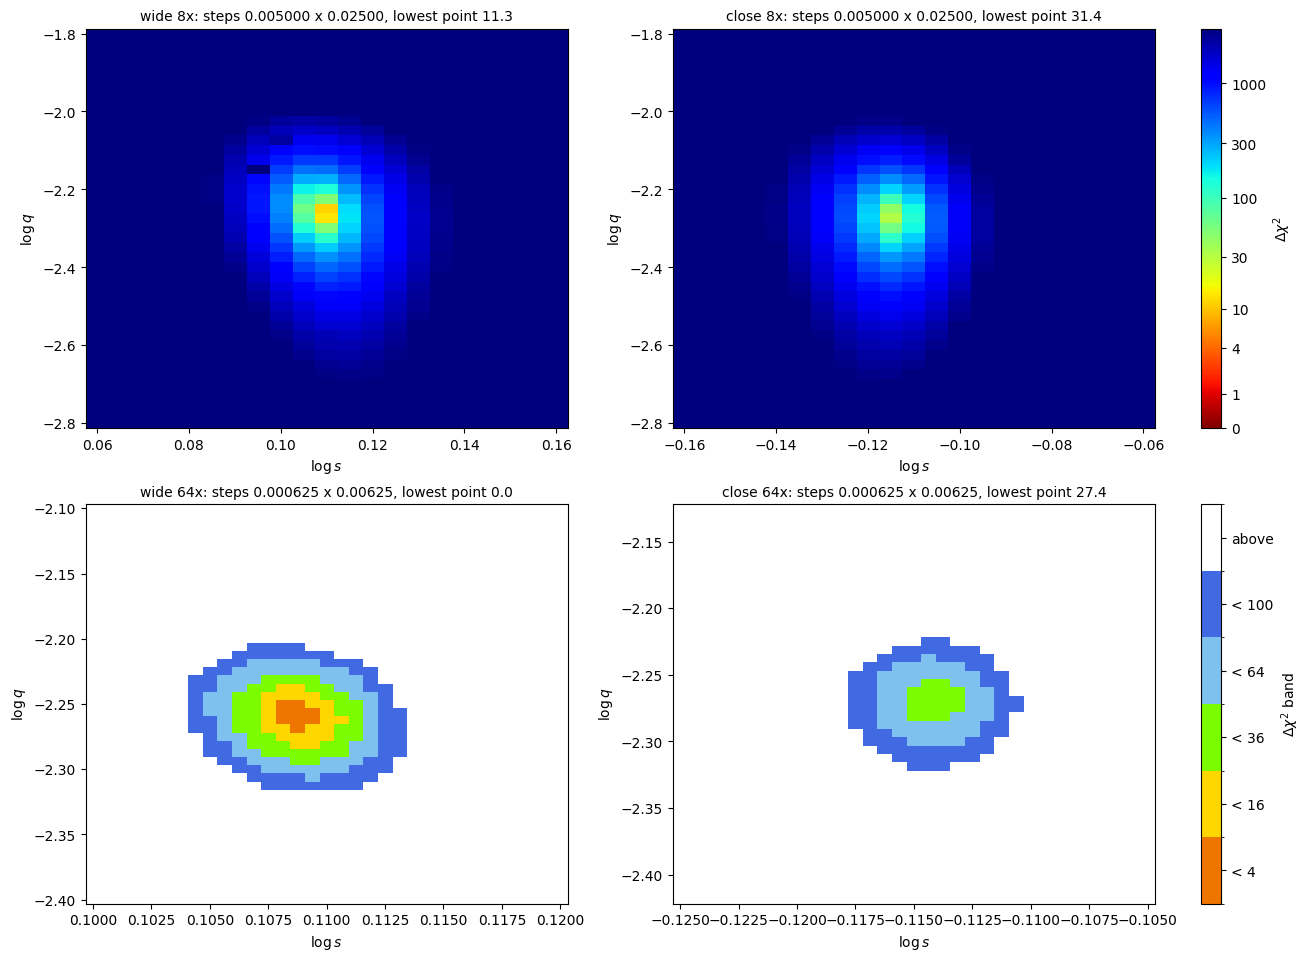

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9.5), constrained_layout=True)
for ax, (name, m) in zip(axs.ravel(), MAPS[1:]):
    if "8x" in name:
        figures.plot_map(m, ax=ax, vmax=3000, chi2_ref=ref, colorbar=(ax is axs[0, 1]))
    else:
        figures.plot_map(m, bands=(4, 16, 36, 64, 100), ax=ax, chi2_ref=ref, colorbar=(ax is axs[1, 1]))
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.6f} x {m['logq'][1] - m['logq'][0]:.5f}, "
                 f"lowest point {np.nanmin(m['chi2']) - ref:.1f}", fontsize=10)

Top: the 8× boxes on a log scale up to 3000; bottom: the 64× boxes with Δχ² bands 4, 16, 36, 64, 100. At 8× each
stripe is still a single column of low values, 11 (wide) and 31 (close) above the best fit. The 64× boxes resolve
each into one closed, nearly round minimum. The wide minimum, at log *s* = +0.1088 and log *q* = −2.263, is the
global one; the close minimum, at log *s* = −0.1144 and log *q* = −2.269, is 28 above it. Δχ² < 4 spans only
±0.0006 dex in log *s* and ±0.01 dex in log *q*; Δχ² < 100 spans about ±0.0045 and ±0.05.

A valley narrower than a lattice step is a known weakness of any fixed lattice: the coarse map shows *where* the
solutions are (the stripes), but not how good they are. Here the guided fits had already found both minima, and the
stripes in the coarse map point straight at them.

## 6. The best fit

In [10]:
best_file = "data/rmdc1279_best.json"
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the two solutions")
    out = {}
    for name, m, extra in (("wide", mapw64, best_first), ("close", mapc64, close_first)):
        i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
        x = m["pars"][i, j]
        starts = [np.array([x[0], x[1], x[2], m["logs"][i], m["logq"][j], x[3], x[4]]), extra]
        c_b, p_b = min((lenscape.fit_full(data, p, be, rounds=3, maxfev=6000) for p in starts), key=lambda r: r[0])
        c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
        out[name] = dict(p_binned=list(p_b), p_season=list(p_s))
    json.dump(dict(p_binned=out["wide"]["p_binned"], p_season=out["wide"]["p_season"], close=out["close"]),
              open(best_file, "w"), indent=1)
bj = json.load(open(best_file))
best, close = np.array(bj["p_season"]), np.array(bj["close"]["p_season"])
for name, p in (("wide", best), ("close", close)):
    print(f"{name}: t0 = {p[0]:.4f}, u0 = {p[1]:+.5f}, tE = {p[2]:.3f} d, s = {10 ** p[3]:.5f}, q = {10 ** p[4]:.4e}, "
          f"alpha = {p[5] % (2 * np.pi):.4f}, rho = {10 ** p[6]:.3e}")
    print(f"       chi2 season {model.chi2(be, p, season):.1f} (N = {len(season)}), all {model.chi2(be, p, data_all):.1f} "
          f"(N = {len(data_all)})")
r = model.residuals(be, best, season)
for k, n in enumerate(season.names):
    print(f"  wide, {n}: chi2 / N = {np.sum(r[season.idx == k] ** 2):.1f} / {np.sum(season.idx == k)}")
fs, fb = model.fluxes(model.magnification(be, best, season), season)
for k, n in enumerate(season.names):
    print(f"  {n}: source flux {fs[k]:8.4f} uJy ({mag(fs[k]):.2f} AB), blend {fb[k]:8.4f} uJy ({mag(fb[k]):.2f} AB)")

wide: t0 = 1874.7853, u0 = -0.01779, tE = 6.362 d, s = 1.28448, q = 5.5039e-03, alpha = 1.3178, rho = 1.800e-03
       chi2 season 7853.0 (N = 8155), all 49184.6 (N = 49488)
close: t0 = 1874.7887, u0 = +0.01479, tE = 6.454 d, s = 0.76864, q = 5.3612e-03, alpha = 4.9702, rho = 1.732e-03
       chi2 season 7880.5 (N = 8155), all 49212.0 (N = 49488)
  wide, F087: chi2 / N = 249.6 / 241
  wide, F146: chi2 / N = 7363.6 / 7674
  wide, F213: chi2 / N = 239.8 / 240
  F087: source flux   0.2449 uJy (25.43 AB), blend   7.3559 uJy (21.73 AB)
  F146: source flux   1.0743 uJy (23.82 AB), blend  32.5384 uJy (20.12 AB)
  F213: source flux   1.4627 uJy (23.49 AB), blend 156.1349 uJy (18.42 AB)


| parameter | wide (best) | close |
|---|---|---|
| *t*₀ (BJD′) | 1874.785 | 1874.789 |
| *u*₀ | −0.0178 | +0.0148 |
| *t*ₑ | 6.36 d | 6.45 d |
| *s* | 1.2845 | 0.7686 |
| *q* | 5.50 × 10⁻³ | 5.36 × 10⁻³ |
| α | 1.318 rad | 4.970 rad |
| ρ | 1.80 × 10⁻³ | 1.73 × 10⁻³ |
| χ² (all 49 488 points) | 49 184.6 | +27.4 |

χ²/N is 0.96–1.04 in each filter. The close solution has *s* ≈ 1/1.30, nearly the inverse of the wide one, and the
same *q*. Its Δχ² = 27 holds on the binned data, the season and all six seasons alike, so the data prefer the wide
solution, though not overwhelmingly.

The source is faint: 23.8 mag in F146, against a blend of 20.1 mag. Most of the baseline light comes from other
stars, which is why the light curve rises only by a factor of about 5 at a magnification above 100.

## 7. The light curve

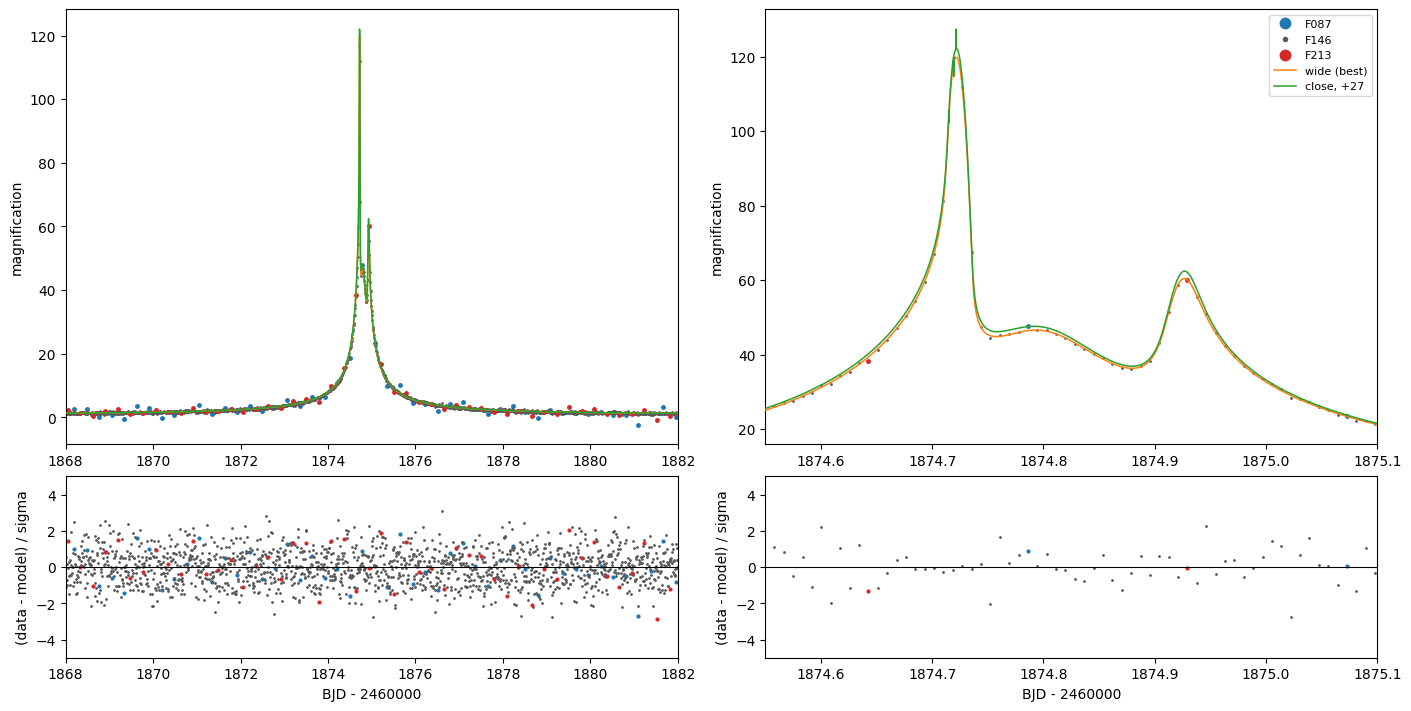

In [11]:
def plot_lc(sols, d=season, window=(1868, 1882), zoom=(1874.55, 1875.1)):
    # all filters as magnifications implied by each point (for the first solution); models; residuals of the first
    p = sols[0][1]
    fs, fb = model.fluxes(model.magnification(be, p, d), d)
    fig = plt.figure(figsize=(14, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1])
    res = model.residuals(be, p, d)
    for col, (a, b) in enumerate((window, zoom)):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            ax.plot(d.t[m], (d.f[m] - fb[k]) / fs[k], ".", ms=2 if n == "F146" else 5, color=c, label=n, zorder=2)
            axr.plot(d.t[m], res[m], ".", ms=2 if n == "F146" else 4, color=c)
        tt = np.linspace(a, b, 6000)
        for (lab, q), c in zip(sols, ("C1", "C2")):
            ax.plot(tt, be.lc(model.clamp(q)[0], tt), color=c, lw=1.1, label=lab, zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("magnification")
        axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
        axr.set_ylabel("(data - model) / sigma"); axr.set_xlabel("BJD - 2460000")
    ax.legend(fontsize=8, markerscale=3)
    return fig

plot_lc([("wide (best)", best), ("close, +27", close)]);

The light curve is drawn as magnification (the flux of each point with the fitted blend removed and divided by the
source flux), so the three filters fall on one curve; F087 scatters more because the source is faint in it. The
model follows the whole peak: the first spike to magnification 120 at BJD′ 1874.72, the fall to 45, the broad shoulder
(47 at 1874.79), the dip to 36, and the second spike to 60 at 1874.93. The residuals are flat in all three
filters. The close solution (green) is almost indistinguishable at this scale; it differs in the details of the
spikes.

## 8. The caustic and the source trajectory

caustic curves (wide): 2


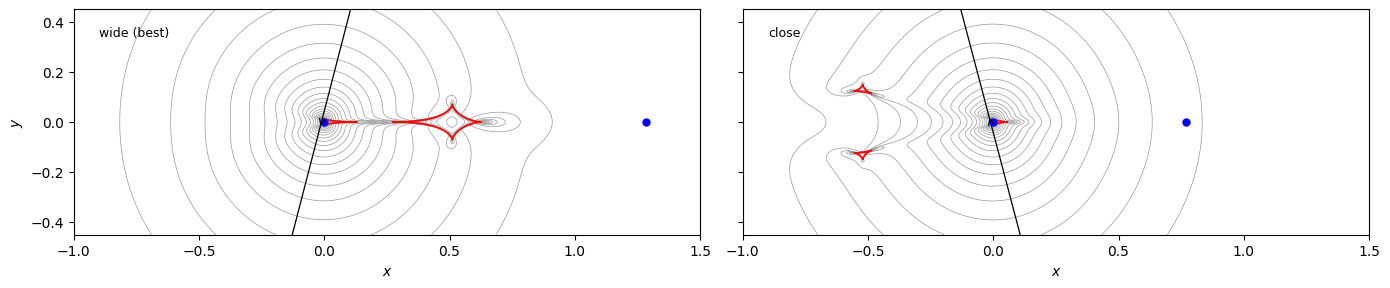

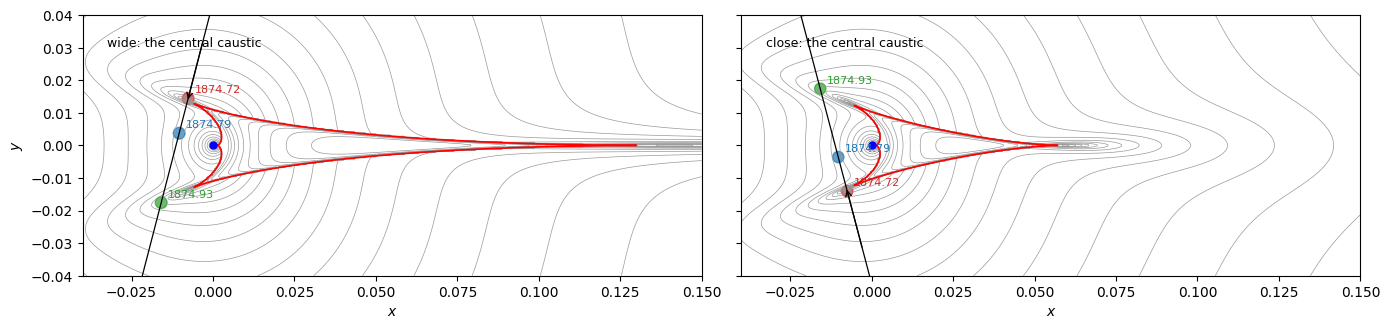

In [12]:
fig = figures.plot_geometry([best, close], labels=["wide (best)", "close"], ncols=2, figsize=(14, 4.2),
                            extent=(-1.0, 1.5, -0.45, 0.45))
fig = figures.plot_geometry([best, close], labels=["wide: the central caustic", "close: the central caustic"], ncols=2,
                            figsize=(14, 4.6), extent=(-0.04, 0.15, -0.04, 0.04), t_arrow=1874.6)
for ax, p in zip(fig.axes, (best, close)):
    x0 = caustics.lens_positions(10 ** p[3], 10 ** p[4])[0]
    for t, c in ((1874.72, "C3"), (1874.79, "C0"), (1874.93, "C2")):
        z = caustics.trajectory(p, [t])[0]
        ax.add_patch(plt.Circle((z.real - x0, z.imag), 10 ** p[6], color=c, alpha=0.7))
        ax.annotate(f"{t:.2f}", (z.real - x0, z.imag), xytext=(5, 4), textcoords="offset points", fontsize=8, color=c)
print("caustic curves (wide):", len(caustics.caustics(10 ** best[3], 10 ** best[4], 500)))

Top: the whole system. In the wide solution the planet is at *x* = 1.28 Einstein radii from the host (origin) and
has its own planetary caustic at *x* ≈ 0.3–0.6, which the source never comes near; in the close solution the
planet is inside the Einstein ring and produces two small triangular caustics on the far side of the host. Bottom: the central
caustic, an elongated arrowhead 0.14 Einstein radii long and 0.026 wide, pointing towards the planet. The source
(coloured discs: its size at the times of the two spikes and the shoulder) moves nearly perpendicular to the planet–host axis
behind the caustic, on the side away from the planet. It passes **1.2 source radii** from the upper back cusp
(the first and highest spike, BJD′ 1874.72), crosses the axis just behind the caustic (the shoulder), and passes
about 5 source radii from the lower back cusp (the second spike, BJD′ 1874.93). It never crosses the
caustic, but its size matters at the first cusp, so ρ is measured.

## 9. What kind of system is this?

**Measured.** A companion with *q* = 5.5 × 10⁻³ of its host's mass (about 6 times the Jupiter–Sun ratio) at
*s* = 1.28 Einstein radii (or 0.77, less favoured by Δχ² = 27). *t*ₑ = 6.4 d, and the source takes
ρ *t*ₑ = 16 minutes to cross its radius.

**Physical scale (rough).** The fit gives the source 23.82 mag in F146 (AB). With the challenge's extinction
(0.57 mag) and a source at 8 kpc, its absolute F146 magnitude is 8.7, four magnitudes fainter than the Sun in the
near infrared (*H*_AB ≈ 4.7). With the Sun's surface brightness that is about 0.16 solar radii (a late M dwarf;
the surface brightness of such a star differs from the Sun's, so this is only an order of magnitude), and
θ⋆ ≈ 0.09 µas. With ρ that gives θₑ ≈ 0.05 mas and a relative proper motion μ ≈ 3 mas/yr.

In [13]:
A146 = 0.575                                   # extinction in F146 from the challenge's photometry table
M146 = mag(fs[1]) - A146 - 5 * np.log10(8000 / 10)                # source at 8 kpc
theta_s = 0.581e-3 * 10 ** (-(M146 - 4.71) / 5)                   # mas; 0.581 micro-arcsec = 1 R_sun at 8 kpc
theta_E = theta_s / 10 ** best[6]
DS = 8.0
print(f"M_F146 = {M146:.2f}, theta_* = {theta_s * 1e3:.3f} micro-arcsec, theta_E = {theta_E:.4f} mas, "
      f"mu_rel = {theta_E / best[2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (MJup)':>13s} {'M_planet (MEarth)':>17s} {'a_perp (AU)':>11s}")
for DL in (3.0, 5.0, 6.0, 7.0, 7.5):
    M = theta_E ** 2 / (8.144 * (1 / DL - 1 / DS))
    print(f"{DL:9.1f} {M * 1047.6:13.1f} {10 ** best[4] * M * 332946:17.1f} {10 ** best[3] * theta_E * DL:11.2f}")

M_F146 = 8.73, theta_* = 0.091 micro-arcsec, theta_E = 0.0507 mas, mu_rel = 2.9 mas/yr
D_L (kpc) M_host (MJup) M_planet (MEarth) a_perp (AU)
      3.0           1.6               2.8        0.20
      5.0           4.4               7.7        0.33
      6.0           7.9              13.9        0.39
      7.0          18.5              32.3        0.46
      7.5          39.6              69.3        0.49


θₑ is small, about a quarter of RMDC26_001576's, and the proper motion is low. Both point to a low-mass lens close
to the source, in the bulge. For a lens at 6–7.5 kpc the host has 8–40 Jupiter masses, a **brown dwarf**, and the
companion 14–70 Earth masses (Neptune to Saturn mass) at a projected 0.4–0.5 AU. A nearer lens would need an even
lighter host (2–4 Jupiter masses at 3–5 kpc), which is unlikely. The usual caveats apply, more so here: θ⋆ rests on
one filter, the Sun's surface brightness for a much cooler star and an assumed source distance, and parallax is not
fitted. A factor of two in θ⋆ is a factor of four in mass.

## 10. Summary

* The peak of this high-magnification event breaks up into two spikes and a shoulder within five hours. The angle-screen guided
  starts fail on it; **caustic-crossing starts** built from the times of two spikes find the solution directly.
* The map has a close/wide pair at log *s* = −0.114 and +0.109, both with *q* = 5.5 × 10⁻³; the wide solution is
  preferred by Δχ² = 27 on all 49 488 points (χ²/N = 0.99).
* The two valleys are **narrower than the coarse lattice step**: the coarse map shows them as thin stripes at about
  230 above the minimum, and only 64× zooms resolve them. All maps together took 30 minutes.
* The source passes 1.2 source radii from a cusp of the central caustic at magnification 120. A rough scale suggests
  a brown-dwarf host with a Neptune-to-Saturn-mass companion in the bulge.
* Not done: parallax, MCMC uncertainties, limb darkening, a proper physical analysis.

**References.** Cassan, A. 2008, A&A, 491, 587. Penny, M. T., et al. 2019, ApJS, 241, 3. Roman Microlensing Data
Challenge 2026, RGES-PIT, [rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).